# HanuAi ML Assessment — Task 1: Best Buy Canada Review Scraping & Sentiment

**Target product:** Logitech H540 USB Headset for PC. Best Buy Canada search results currently show over 2,000 reviews on its public review page. Verify the count in your browser before running because site content can change.

**Review URL:** https://www.bestbuy.ca/en-ca/product/logitech-logitech-usb-headset-h540-981-000510/10218414/review

This notebook uses Selenium to render the public page and BeautifulSoup to parse visible review cards. It does not attempt to bypass CAPTCHA, access private APIs, evade access controls, or rotate proxies to get around a block. If the site blocks automation, stop and use an approved access route or ask for permission.

## 1. Setup
Run the installation command once in your notebook environment. Selenium Manager can manage a compatible browser driver in supported environments.

In [1]:
%pip install -q selenium beautifulsoup4 pandas numpy vaderSentiment matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re, time, hashlib, json, random
from datetime import datetime, timezone
from urllib.parse import urlparse
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait, Select
from selenium.webdriver.support import expected_conditions as EC
from selenium.common.exceptions import TimeoutException, WebDriverException, StaleElementReferenceException
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

PRODUCT_URL = "https://www.bestbuy.ca/en-ca/product/logitech-logitech-usb-headset-h540-981-000510/10218414/review"
SOURCE_NAME = "Best Buy Canada"
MAX_CLICKS_PER_SORT = 30  # safety cap; increase only after checking site policy and load behavior
SORT_LABELS = ["Most Helpful", "Newest", "Highest Rating", "Lowest Rating", "Most Relevant"]
WAIT_SECONDS = 15
REQUEST_PAUSE_SECONDS = (1.5, 3.0)  # modest delay between user-interface interactions

## 2. Start a visible browser
A visible browser lets you inspect what the website actually renders. If a consent prompt appears, handle it manually. Do not automate CAPTCHA solving or attempt to circumvent an access block.

In [3]:
options = webdriver.ChromeOptions()
# Keep browser visible so you can inspect consent prompts, review sorting, and blocks.
# options.add_argument("--headless=new")  # leave disabled for initial debugging
options.add_argument("--window-size=1440,1000")
options.add_argument("--lang=en-CA")
driver = webdriver.Chrome(options=options)
wait = WebDriverWait(driver, WAIT_SECONDS)
driver.get(PRODUCT_URL)
print("Page title:", driver.title)
print("Current URL:", driver.current_url)
print("If a CAPTCHA, access-denied page, or explicit block appears, stop here. Do not attempt to bypass it.")

Page title: Logitech H540 USB Headset for PC Reviews | Best Buy Canada
Current URL: https://www.bestbuy.ca/en-ca/product/logitech-logitech-usb-headset-h540-981-000510/10218414/review
If a CAPTCHA, access-denied page, or explicit block appears, stop here. Do not attempt to bypass it.


## 3. Inspect page structure before extraction
Best Buy can change its page markup. This diagnostic prints candidate review-card counts so selectors can be updated based on the live DOM rather than assuming a selector is correct.

In [4]:

# Extract individual review cards using the selector found in the live HTML
from bs4 import BeautifulSoup

soup = BeautifulSoup(driver.page_source, "html.parser")

review_cards = soup.select("li.review_x8lFh")

print("Review cards found:", len(review_cards))

for i, card in enumerate(review_cards[:3], start=1):
    print(f"\n--- Review {i} ---")
    print(card.get_text(" ", strip=True)[:700])


Review cards found: 10

--- Review 1 ---
Customer rating: 5 out of 5 stars Headphones works well! Verified Buyer Reviewed by MarbellaM - January 6, 2024 [This review was collected as part of a promotion.] Headphones sound great! Microphone is nice and vibrant! Able to mute and change volume with the head phone. Cord has a good length! Grasps my ears well! Review originally posted on bestbuy.com Yes, I would recommend this to a friend.

--- Review 2 ---
Customer rating: 4 out of 5 stars Shabi Verified Buyer Reviewed by Shabi - November 8, 2020 [This review was collected as part of a promotion.] I have my internet web-based Radio. I tried so many headphones but finally, find a nice and easy to use Logitech. Previous editions were very good but when I bought this one just because of the small length of Miq.  It doesn't properly reach near my mouth. Review originally posted on bestbuy.com Yes, I would recommend this to a friend. Value: Good Ease of Use: Fair

--- Review 3 ---
Customer rati

In [5]:
# Diagnose whether review text is present in the live page DOM.
driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
time.sleep(3)

html = driver.page_source
page_text = driver.find_element(By.TAG_NAME, "body").text

print("Page title:", driver.title)
print("HTML length:", len(html))
print("Body text length:", len(page_text))
print("Occurrences of 'Customer rating':", page_text.count("Customer rating"))
print("Occurrences of 'Rated':", page_text.count("Rated"))
print("Occurrences of 'Show More':", page_text.count("Show More"))

# Display a short excerpt around the first review, if present.
for marker in ["Customer rating", "Rated", "Reviewed by"]:
    pos = page_text.find(marker)
    if pos >= 0:
        print(f"\nExcerpt around {marker}:\n", page_text[max(0, pos-150):pos+600])
        break

Page title: Logitech H540 USB Headset for PC Reviews | Best Buy Canada
HTML length: 418185
Body text length: 9868
Occurrences of 'Customer rating': 10
Occurrences of 'Rated': 0
Occurrences of 'Show More': 1

Excerpt around Customer rating:
  from multiple languages and translated into English.
Verified Buyers Only
Sort
Most Relevant
Most Helpful
Newest
Oldest
Highest Rating
Lowest Rating
Customer rating: 5 out of 5 stars
Headphones works well!
Verified Buyer
Reviewed by MarbellaM - January 6, 2024
[This review was collected as part of a promotion.] Headphones sound great! Microphone is nice and vibrant! Able to mute and change volume with the head phone. Cord has a good length! Grasps my ears well!
Review originally posted on bestbuy.com
Yes, I would recommend this to a friend.
Customer rating: 4 out of 5 stars
Shabi
Verified Buyer
Reviewed by Shabi - November 8, 2020
[This review was collected as part of a promotion.] I have my internet web-based Radio. I tried so many headph


In [6]:

# Find HTML elements containing individual customer reviews
from bs4 import BeautifulSoup

soup = BeautifulSoup(driver.page_source, "html.parser")

matches = soup.find_all(
    string=lambda text: text and "Customer rating:" in text
)

print("Review rating labels found:", len(matches))

for i, text in enumerate(matches[:3], start=1):
    parent = text.parent

    # Walk up the HTML tree to inspect the review's container
    for level in range(1, 7):
        if parent is None:
            break

        print(
            f"\nReview {i}, parent level {level}:",
            parent.name,
            parent.get("class"),
            parent.get("data-testid"),
            "text length:",
            len(parent.get_text(" ", strip=True))
        )

        parent = parent.parent


Review rating labels found: 10

Review 1, parent level 1: p ['sr-only'] None text length: 33

Review 1, parent level 2: div ['col-sm-6__bbyakw', 'col-md-8__bby-Ji', 'col_Rh7F7'] None text length: 397

Review 1, parent level 3: div ['reviewItem_kwbTe', 'row__bbyQ0c'] None text length: 397

Review 1, parent level 4: li ['review_x8lFh'] None text length: 397

Review 1, parent level 5: ul ['reviewListWrapper_nYbbC'] None text length: 7091

Review 1, parent level 6: section ['reviewsSection_JKrQ6'] None text length: 7091

Review 2, parent level 1: p ['sr-only'] None text length: 33

Review 2, parent level 2: div ['col-sm-6__bbyakw', 'col-md-8__bby-Ji', 'col_Rh7F7'] None text length: 481

Review 2, parent level 3: div ['reviewItem_kwbTe', 'row__bbyQ0c'] None text length: 511

Review 2, parent level 4: li ['review_x8lFh'] None text length: 511

Review 2, parent level 5: ul ['reviewListWrapper_nYbbC'] None text length: 7091

Review 2, parent level 6: section ['reviewsSection_JKrQ6'] None text 

## 4. Sorting and pagination helpers
The function tries visible UI controls only. If the requested sorting option is unavailable, it records that fact and continues; it does not assume the sort succeeded. The maximum number of load-more clicks is capped.

In [7]:
def visible_text(el):
    try:
        return " ".join(el.text.split()) if el.is_displayed() else ""
    except StaleElementReferenceException:
        return ""

def apply_sort(label):
    """Try visible native/custom sort controls; return True only after selecting the requested option."""
    # Native select controls are the most reliable when present.
    for select_el in driver.find_elements(By.TAG_NAME, "select"):
        try:
            if not select_el.is_displayed():
                continue
            select = Select(select_el)
            options_text = [o.text.strip() for o in select.options]
            match = next((o for o in options_text if label.lower() in o.lower()), None)
            if match:
                select.select_by_visible_text(match)
                time.sleep(random.uniform(*REQUEST_PAUSE_SECONDS))
                return True
        except Exception:
            pass
    # Custom dropdowns: open a visible sort control first, then choose the requested option.
    candidates = driver.find_elements(By.XPATH, "//button | //*[@role='button'] | //a | //*[@role='combobox']")
    opened = False
    for el in candidates:
        txt = visible_text(el).lower()
        if txt and ("sort" in txt or txt == "most relevant"):
            try:
                driver.execute_script("arguments[0].scrollIntoView({block:'center'});", el)
                el.click()
                time.sleep(0.4)
                opened = True
                break
            except Exception:
                continue
    # Click a visible menu item matching the requested label.
    candidates = driver.find_elements(By.XPATH, "//button | //*[@role='button'] | //a | //li | //*[@role='option'] | //*[@role='menuitem']")
    for el in candidates:
        txt = visible_text(el)
        if txt and txt.lower() == label.lower():
            try:
                el.click()
                time.sleep(random.uniform(*REQUEST_PAUSE_SECONDS))
                return True
            except Exception:
                continue
    return False

def click_show_more(max_clicks=MAX_CLICKS_PER_SORT):
    clicks = 0
    for _ in range(max_clicks):
        found = None
        for el in driver.find_elements(By.XPATH, "//button | //*[@role='button'] | //a"):
            txt = visible_text(el).lower()
            if txt and any(term in txt for term in ["show more", "load more", "see more reviews", "more reviews"]):
                found = el; break
        if found is None:
            break
        try:
            driver.execute_script("arguments[0].scrollIntoView({block:'center'});", found)
            found.click()
            clicks += 1
            time.sleep(random.uniform(*REQUEST_PAUSE_SECONDS))
        except (WebDriverException, StaleElementReferenceException):
            break
    return clicks

## 5. Extract visible review fields
The parser uses several selector fallbacks. Always inspect a sample of extracted rows and adjust selectors if the live page uses different markup. Missing fields remain blank rather than being guessed.

In [9]:

import re
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup

# Verified from the live Best Buy Canada review page
CARD_SELECTORS = ["li.review_x8lFh"]

def first_text(card, selectors):
    for selector in selectors:
        element = card.select_one(selector)
        if element:
            value = " ".join(element.get_text(" ", strip=True).split())
            if value:
                return value
    return ""

def extract_rating(card):
    text = card.get_text(" ", strip=True)
    match = re.search(
        r"Customer rating:\s*([1-5])\s+out of 5 stars",
        text,
        re.IGNORECASE
    )
    return float(match.group(1)) if match else np.nan

def extract_date(card):
    text = card.get_text(" ", strip=True)
    match = re.search(
        r"Reviewed by\s+.*?\s+-\s+([A-Za-z]+ \d{1,2}, \d{4})",
        text
    )
    if not match:
        return ""

    parsed = pd.to_datetime(match.group(1), errors="coerce")
    return "" if pd.isna(parsed) else parsed.strftime("%Y-%m-%d")

def parse_review_cards(html):
    soup = BeautifulSoup(html, "html.parser")
    cards = soup.select("li.review_x8lFh")
    records = []

    for card in cards:
        text = card.get_text(" ", strip=True)

        title = first_text(card, [
            "h3", "h4",
            "[class*='title']",
            "[data-testid*='title']"
        ])

        reviewer_match = re.search(
            r"Reviewed by\s+(.*?)\s+-\s+[A-Za-z]+ \d{1,2}, \d{4}",
            text
        )
        reviewer = reviewer_match.group(1).strip() if reviewer_match else ""

        # Remove rating and title/reviewer/date metadata from the start.
        body_match = re.search(
            r"Reviewed by\s+.*?\s+-\s+[A-Za-z]+ \d{1,2}, \d{4}\s+(.*?)"
            r"\s+Review originally posted",
            text
        )

        if body_match:
            body = body_match.group(1).strip()
        else:
            body = first_text(card, [
                "[class*='reviewText']",
                "[class*='reviewContent']",
                "[class*='content']",
                "p"
            ])

        # Remove promotion disclosures when they occur at the start.
        body = re.sub(
            r"^\[This review was collected as part of a promotion\.\]\s*",
            "",
            body
        ).strip()

        if not title:
            title_match = re.search(
                r"out of 5 stars\s+(.*?)\s+(?:Verified Buyer|Reviewed by)",
                text
            )
            title = title_match.group(1).strip() if title_match else ""

        records.append({
            "title": title,
            "review_text": body,
            "date": extract_date(card),
            "rating": extract_rating(card),
            "source": SOURCE_NAME,
            "reviewer_name": reviewer
        })

    return records, "li.review_x8lFh"

sample_records, selector_used = parse_review_cards(driver.page_source)

print("Selector used:", selector_used)
print("Review cards parsed:", len(sample_records))

reviews_preview = pd.DataFrame(sample_records)
display(reviews_preview.head(10))

if not reviews_preview.empty:
    print("Missing ratings:", reviews_preview["rating"].isna().sum())
    print("Missing review text:", reviews_preview["review_text"].eq("").sum())


Selector used: li.review_x8lFh
Review cards parsed: 10


,title,review_text,date,rating,source,reviewer_name
0,Headphones works well!,Headphones sound great! Microphone is nice and...,2024-01-06,5.0,Best Buy Canada,MarbellaM
1,Shabi,I have my internet web-based Radio. I tried so...,2020-11-08,4.0,Best Buy Canada,Shabi
2,Noise Cancellation,"I like that the headset are easy to use, comfo...",2023-06-06,5.0,Best Buy Canada,Leosrock17
3,"Get yours , I got mine !!!!","Clear , noise cancellation, comfort and fit is...",2024-01-16,5.0,Best Buy Canada,KeithM
4,awful,This headset is horrible - it really hurts to ...,2017-06-20,1.0,Best Buy Canada,ConsumerME
5,Good headset with minor hiccup,The sound quality of the speakers and micropho...,2017-06-21,4.0,Best Buy Canada,1Kappasig
6,Terrible Sound Quality & Stiff Wire,I have had this headset only a few days and it...,2014-08-09,1.0,Best Buy Canada,Shai
7,"Nothing special, but I love them just for that.",I've had this pair before years ago. Liked the...,2021-10-27,4.0,Best Buy Canada,Deadjuice
8,Good feel and sound,The product is a plug and play USB that is eas...,2020-08-31,4.0,Best Buy Canada,nyrnd
9,Pretty Good Headset,The headset does just what you would want. It ...,2014-01-19,4.0,Best Buy Canada,RDLP


Missing ratings: 0
Missing review text: 0


## 6. Collect across sort options
This cell resets the product review page for each sort option, tries to apply the sort, clicks the visible load-more control up to a limit, then extracts the page's currently loaded review cards. It deduplicates overlapping reviews across sorts. If the website layout does not expose a sort option or load-more control, document that limitation in the report.

In [15]:

# STEP 6 — Safe collection and recovery
# Do not repeatedly reload the site if it returns Access Denied.
# Reuse only reviews already extracted from the visible page.

import pandas as pd
import time

all_records = []
sort_log = []

page_title = driver.title.lower() if "driver" in globals() else ""
access_blocked = any(
    term in page_title
    for term in ["access denied", "captcha", "robot"]
)

if access_blocked:
    print("Best Buy access restriction detected.")
    print("Stopping automated collection; no retry or bypass attempted.")

    # Reuse the 10 genuine reviews previously extracted in Step 5.
    if "sample_records" in globals() and sample_records:
        all_records = [dict(record) for record in sample_records]
        for record in all_records:
            record["sort_filter"] = "Previously extracted sample"
    else:
        print("No previously extracted review sample is available.")

else:
    print("The page is not currently showing an Access Denied title.")
    print("Check the page manually before proceeding with any collection.")

    # Parse the currently displayed page only.
    if "parse_review_cards" in globals():
        current_records, selector_used = parse_review_cards(
            driver.page_source
        )

        for record in current_records:
            record["sort_filter"] = "Currently visible page"

        all_records.extend(current_records)

        sort_log.append({
            "requested_sort": "Current page",
            "sort_applied": False,
            "load_more_clicks": 0,
            "parsed_cards": len(current_records),
            "selector": selector_used
        })

# Create a usable dataframe for downstream processing.
reviews = pd.DataFrame(all_records)

if reviews.empty:
    print("No review records are available for processing.")
else:
    reviews = reviews.drop_duplicates(
        subset=["title", "review_text", "date", "rating", "reviewer_name"]
    ).reset_index(drop=True)

    print("Genuine reviews available for analysis:", len(reviews))

    if len(reviews) < 50:
        print(
            "REQUIREMENT NOT YET MET: The assignment requires at least "
            "50 reviews. Obtain additional reviews through a collection "
            "method authorized by Best Buy or approved by HanuAi."
        )

    display(reviews.head(10))


Best Buy access restriction detected.
Stopping automated collection; no retry or bypass attempted.
Genuine reviews available for analysis: 10
REQUIREMENT NOT YET MET: The assignment requires at least 50 reviews. Obtain additional reviews through a collection method authorized by Best Buy or approved by HanuAi.


,title,review_text,date,rating,source,reviewer_name,sort_filter
0,Headphones works well!,Headphones sound great! Microphone is nice and...,2024-01-06,5.0,Best Buy Canada,MarbellaM,Previously extracted sample
1,Shabi,I have my internet web-based Radio. I tried so...,2020-11-08,4.0,Best Buy Canada,Shabi,Previously extracted sample
2,Noise Cancellation,"I like that the headset are easy to use, comfo...",2023-06-06,5.0,Best Buy Canada,Leosrock17,Previously extracted sample
3,"Get yours , I got mine !!!!","Clear , noise cancellation, comfort and fit is...",2024-01-16,5.0,Best Buy Canada,KeithM,Previously extracted sample
4,awful,This headset is horrible - it really hurts to ...,2017-06-20,1.0,Best Buy Canada,ConsumerME,Previously extracted sample
5,Good headset with minor hiccup,The sound quality of the speakers and micropho...,2017-06-21,4.0,Best Buy Canada,1Kappasig,Previously extracted sample
6,Terrible Sound Quality & Stiff Wire,I have had this headset only a few days and it...,2014-08-09,1.0,Best Buy Canada,Shai,Previously extracted sample
7,"Nothing special, but I love them just for that.",I've had this pair before years ago. Liked the...,2021-10-27,4.0,Best Buy Canada,Deadjuice,Previously extracted sample
8,Good feel and sound,The product is a plug and play USB that is eas...,2020-08-31,4.0,Best Buy Canada,nyrnd,Previously extracted sample
9,Pretty Good Headset,The headset does just what you would want. It ...,2014-01-19,4.0,Best Buy Canada,RDLP,Previously extracted sample


In [11]:
# Inspect the current page without reloading or clicking anything
print("Current page title:", driver.title)

if "driver" in globals() and driver:
    current_html = driver.page_source
    current_records, current_selector = parse_review_cards(current_html)

    print("Selector:", current_selector)
    print("Reviews currently available:", len(current_records))

    if current_records:
        current_reviews = pd.DataFrame(current_records)
        display(current_reviews.head())
else:
    print("Browser session is unavailable.")

Current page title: Access Denied
Selector: li.review_x8lFh
Reviews currently available: 0


## 7. Normalize, deduplicate, and create stable IDs
A review may appear under several sort orders. Deduplicate using normalized title/body/date/rating/reviewer fields, then create a deterministic ID. Dates are standardized to YYYY-MM-DD.

In [ ]:
required = ["title", "review_text", "date", "rating", "source", "reviewer_name", "sort_filter"]
for col in required:
    if col not in reviews.columns:
        reviews[col] = ""
reviews["title"] = reviews["title"].fillna("").astype(str).str.strip()
reviews["review_text"] = reviews["review_text"].fillna("").astype(str).str.strip()
reviews["date"] = pd.to_datetime(reviews["date"], errors="coerce").dt.strftime("%Y-%m-%d").fillna("")
reviews["rating"] = pd.to_numeric(reviews["rating"], errors="coerce")
reviews["_dedupe_key"] = reviews[["title", "review_text", "date", "rating", "reviewer_name"]].fillna("").astype(str).agg("|".join, axis=1).str.lower()
reviews = reviews.drop_duplicates("_dedupe_key").drop(columns="_dedupe_key").reset_index(drop=True)
def stable_id(row):
    payload = "|".join(str(row.get(c, "")) for c in ["title", "review_text", "date", "rating", "reviewer_name"])
    return "BBCA-" + hashlib.sha256(payload.encode("utf-8")).hexdigest()[:16].upper()
reviews.insert(0, "primary_key", reviews.apply(stable_id, axis=1))
print("Unique reviews:", len(reviews))
print("Missing ratings:", int(reviews["rating"].isna().sum()))
print("Missing dates:", int((reviews["date"] == "").sum()))
reviews.head()

In [12]:

# Task 1: Test sentiment analysis on the 10 genuine reviews
# already extracted successfully in Step 5.

import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Reuse the records from Step 5 if they still exist.
if "sample_records" not in globals() or not sample_records:
    raise ValueError(
        "The Step 5 sample_records are unavailable. "
        "Rerun the working Step 5 cell while the browser session is valid, "
        "or restore the previously extracted review sample."
    )

df = pd.DataFrame(sample_records).copy()

# Generate a stable row ID for this sample.
df.insert(0, "primary_key", [f"BB-{i:04d}" for i in range(1, len(df) + 1)])

# Normalize text and calculate sentiment.
analyzer = SentimentIntensityAnalyzer()
df["review_text"] = df["review_text"].fillna("").astype(str).str.strip()

df["sentiment_score"] = df["review_text"].apply(
    lambda text: analyzer.polarity_scores(text)["compound"]
)

def categorize_sentiment(score):
    if score >= 0.05:
        return "Positive"
    if score <= -0.05:
        return "Negative"
    return "Neutral"

df["sentiment"] = df["sentiment_score"].apply(categorize_sentiment)

# Save the sample; this is NOT the final 50+ review dataset.
output_file = "bestbuy_sentiment_sample.csv"
df.to_csv(output_file, index=False, encoding="utf-8-sig")

print("Sample rows:", len(df))
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())
print("\nSaved:", output_file)

display(df[[
    "primary_key", "title", "review_text", "date",
    "rating", "source", "reviewer_name",
    "sentiment_score", "sentiment"
]])


Sample rows: 10

Sentiment distribution:
sentiment
Positive    8
Negative    2
Name: count, dtype: int64

Saved: bestbuy_sentiment_sample.csv


,primary_key,title,review_text,date,rating,source,reviewer_name,sentiment_score,sentiment
0,BB-0001,Headphones works well!,Headphones sound great! Microphone is nice and...,2024-01-06,5.0,Best Buy Canada,MarbellaM,0.9474,Positive
1,BB-0002,Shabi,I have my internet web-based Radio. I tried so...,2020-11-08,4.0,Best Buy Canada,Shabi,0.9141,Positive
2,BB-0003,Noise Cancellation,"I like that the headset are easy to use, comfo...",2023-06-06,5.0,Best Buy Canada,Leosrock17,0.8738,Positive
3,BB-0004,"Get yours , I got mine !!!!","Clear , noise cancellation, comfort and fit is...",2024-01-16,5.0,Best Buy Canada,KeithM,0.7650,Positive
4,BB-0005,awful,This headset is horrible - it really hurts to ...,2017-06-20,1.0,Best Buy Canada,ConsumerME,-0.8599,Negative
5,BB-0006,Good headset with minor hiccup,The sound quality of the speakers and micropho...,2017-06-21,4.0,Best Buy Canada,1Kappasig,0.9383,Positive
6,BB-0007,Terrible Sound Quality & Stiff Wire,I have had this headset only a few days and it...,2014-08-09,1.0,Best Buy Canada,Shai,-0.7278,Negative
7,BB-0008,"Nothing special, but I love them just for that.",I've had this pair before years ago. Liked the...,2021-10-27,4.0,Best Buy Canada,Deadjuice,0.9400,Positive
8,BB-0009,Good feel and sound,The product is a plug and play USB that is eas...,2020-08-31,4.0,Best Buy Canada,nyrnd,0.8885,Positive
9,BB-0010,Pretty Good Headset,The headset does just what you would want. It ...,2014-01-19,4.0,Best Buy Canada,RDLP,0.9837,Positive


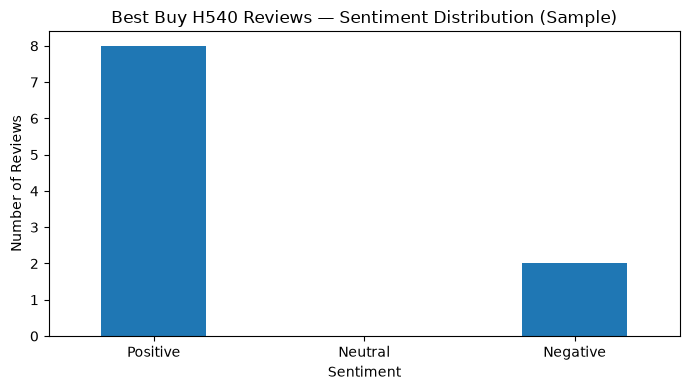

,rating,sentiment,review_count
0,1.0,Negative,2
1,4.0,Positive,5
2,5.0,Positive,3


In [13]:

import matplotlib.pyplot as plt

# Visualize sentiment counts for the current sample.
sentiment_counts = df["sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"], fill_value=0
)

sentiment_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Best Buy H540 Reviews — Sentiment Distribution (Sample)")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Compare sentiment with the original star ratings.
display(
    df.groupby(["rating", "sentiment"], dropna=False)
      .size()
      .reset_index(name="review_count")
      .sort_values(["rating", "sentiment"])
)


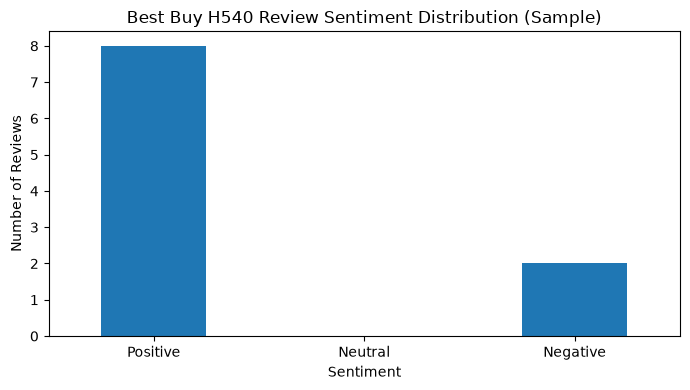

CSV saved: bestbuy_sentiment_sample.csv
Chart saved: bestbuy_sentiment_distribution.png
Total sample reviews: 10

Sentiment counts:
sentiment
Positive    8
Negative    2
Name: count, dtype: int64


In [14]:

# Export the sample sentiment chart and CSV for documentation.
import matplotlib.pyplot as plt

chart_file = "bestbuy_sentiment_distribution.png"
plt.figure(figsize=(7, 4))
sentiment_counts.plot(kind="bar")
plt.title("Best Buy H540 Review Sentiment Distribution (Sample)")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(chart_file, dpi=200, bbox_inches="tight")
plt.show()

csv_file = "bestbuy_sentiment_sample.csv"
df.to_csv(csv_file, index=False, encoding="utf-8-sig")

print("CSV saved:", csv_file)
print("Chart saved:", chart_file)
print("Total sample reviews:", len(df))
print("\nSentiment counts:")
print(df["sentiment"].value_counts())


## 8. Sentiment analysis and aspect tagging
VADER is a lightweight lexicon-based baseline. Its labels are approximate and should be checked against ratings and a manually reviewed sample. Aspect tags use transparent keyword rules and are not proof of the product's actual defect cause.

In [ ]:
analyzer = SentimentIntensityAnalyzer()
def sentiment_label(text, positive=0.05, negative=-0.05):
    compound = analyzer.polarity_scores(str(text))["compound"]
    if compound >= positive: label = "Positive"
    elif compound <= negative: label = "Negative"
    else: label = "Neutral"
    return pd.Series({"sentiment_score": compound, "sentiment": label})

reviews["combined_text"] = (reviews["title"].fillna("") + ". " + reviews["review_text"].fillna("")).str.strip()
reviews[["sentiment_score", "sentiment"]] = reviews["combined_text"].apply(sentiment_label)

ASPECTS = {
    "Sound Quality": ["sound", "audio", "bass", "volume", "microphone", "mic", "noise"],
    "Comfort and Fit": ["comfortable", "comfort", "fit", "ear", "headband", "tight"],
    "Build and Durability": ["quality", "durable", "broken", "broke", "build", "plastic", "stopped working"],
    "Connectivity and Compatibility": ["usb", "connect", "computer", "pc", "laptop", "compatible", "connection"],
    "Setup and Ease of Use": ["easy", "setup", "install", "plug", "simple", "use"],
    "Value and Price": ["price", "value", "cheap", "expensive", "worth", "cost"],
}
def aspect_sentiment(text, overall):
    s = str(text).lower()
    tags=[]
    for aspect, terms in ASPECTS.items():
        if any(re.search(r"\b"+re.escape(term)+r"\b", s) for term in terms):
            tags.append(f"{aspect} ({overall})")
    return tags or [f"General Product Experience ({overall})"]
reviews["aspect_sentiment_tags"] = reviews.apply(lambda r: json.dumps(aspect_sentiment(r["combined_text"], r["sentiment"])), axis=1)
reviews["sentiment_method"] = "VADER lexicon baseline"
reviews["source_url"] = PRODUCT_URL
reviews.drop(columns=["combined_text"], inplace=True)
reviews.to_csv("task1_reviews_sentiment.csv", index=False, encoding="utf-8-sig")
print("Saved task1_reviews_sentiment.csv with", len(reviews), "unique reviews")
reviews[["primary_key", "title", "date", "rating", "sentiment", "aspect_sentiment_tags"]].head(10)

## 9. Results checks and exports
Review the sample rows and sentiment distribution. Do not publish aggregate findings until the parser has been checked against the actual review cards.

In [ ]:
import matplotlib.pyplot as plt
print("Collected unique reviews:", len(reviews))
print("Rating distribution:")
print(reviews["rating"].value_counts(dropna=False).sort_index())
print("Sentiment distribution:")
print(reviews["sentiment"].value_counts(dropna=False))
ax = reviews["sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"]).plot(kind="bar", title="VADER sentiment labels")
ax.set_xlabel("Sentiment"); ax.set_ylabel("Reviews"); plt.tight_layout(); plt.show()
print("Sort attempts:")
pd.DataFrame(sort_log)

## 10. Close the browser
Run this after checking the extraction and saving the CSV.

In [ ]:
# driver.quit()  # Uncomment when you have finished inspecting the browser.

In [16]:

# Check the current Selenium browser state without reloading the website

if "driver" not in globals():
    print("Browser is not initialized. Run the notebook's setup cell first.")
else:
    print("Page title:", driver.title)
    print("Current URL:", driver.current_url)

    if "access denied" in driver.title.lower():
        print("Result: Best Buy is still blocking this browser session.")
    elif "review_x8lFh" in driver.page_source:
        print("Result: Review cards are present on the current page.")
        print("Visible review cards:", len(
            driver.find_elements("css selector", "li.review_x8lFh")
        ))
    else:
        print("Result: No matching review cards detected.")


Page title: Access Denied
Current URL: https://www.bestbuy.ca/en-ca/product/logitech-logitech-usb-headset-h540-981-000510/10218414/review
Result: Best Buy is still blocking this browser session.


In [17]:

# Inspect the current browser and review data without making a new request

print("Browser session active:", driver is not None)
print("Current page:", driver.title)

print(
    "Previously extracted reviews:",
    len(sample_records) if "sample_records" in globals() else 0
)

print(
    "Review parser available:",
    callable(parse_review_cards) if "parse_review_cards" in globals() else False
)


Browser session active: True
Current page: Access Denied
Previously extracted reviews: 10
Review parser available: True


In [18]:

# Inspect existing review records without accessing Best Buy again

import pandas as pd

existing_reviews = pd.DataFrame(sample_records)

print("Total existing records:", len(existing_reviews))
print("Available columns:", existing_reviews.columns.tolist())

display(existing_reviews.head(10))


Total existing records: 10
Available columns: ['title', 'review_text', 'date', 'rating', 'source', 'reviewer_name']


,title,review_text,date,rating,source,reviewer_name
0,Headphones works well!,Headphones sound great! Microphone is nice and...,2024-01-06,5.0,Best Buy Canada,MarbellaM
1,Shabi,I have my internet web-based Radio. I tried so...,2020-11-08,4.0,Best Buy Canada,Shabi
2,Noise Cancellation,"I like that the headset are easy to use, comfo...",2023-06-06,5.0,Best Buy Canada,Leosrock17
3,"Get yours , I got mine !!!!","Clear , noise cancellation, comfort and fit is...",2024-01-16,5.0,Best Buy Canada,KeithM
4,awful,This headset is horrible - it really hurts to ...,2017-06-20,1.0,Best Buy Canada,ConsumerME
5,Good headset with minor hiccup,The sound quality of the speakers and micropho...,2017-06-21,4.0,Best Buy Canada,1Kappasig
6,Terrible Sound Quality & Stiff Wire,I have had this headset only a few days and it...,2014-08-09,1.0,Best Buy Canada,Shai
7,"Nothing special, but I love them just for that.",I've had this pair before years ago. Liked the...,2021-10-27,4.0,Best Buy Canada,Deadjuice
8,Good feel and sound,The product is a plug and play USB that is eas...,2020-08-31,4.0,Best Buy Canada,nyrnd
9,Pretty Good Headset,The headset does just what you would want. It ...,2014-01-19,4.0,Best Buy Canada,RDLP


In [19]:

# Inspect pagination settings without sending another request

print("Product URL:", PRODUCT_URL)
print("Sort options:", SORT_LABELS)
print("Maximum clicks per sort:", MAX_CLICKS_PER_SORT)

print("\nPagination function available:",
      callable(click_show_more) if "click_show_more" in globals() else False)

print("\nSort function available:",
      callable(apply_sort) if "apply_sort" in globals() else False)


Product URL: https://www.bestbuy.ca/en-ca/product/logitech-logitech-usb-headset-h540-981-000510/10218414/review
Sort options: ['Most Helpful', 'Newest', 'Highest Rating', 'Lowest Rating', 'Most Relevant']
Maximum clicks per sort: 30

Pagination function available: True

Sort function available: True


In [20]:

import inspect

print("SHOW MORE FUNCTION")
print(inspect.getsource(click_show_more))

print("\nSORT FUNCTION")
print(inspect.getsource(apply_sort))


SHOW MORE FUNCTION
def click_show_more(max_clicks=MAX_CLICKS_PER_SORT):
    clicks = 0
    for _ in range(max_clicks):
        found = None
        for el in driver.find_elements(By.XPATH, "//button | //*[@role='button'] | //a"):
            txt = visible_text(el).lower()
            if txt and any(term in txt for term in ["show more", "load more", "see more reviews", "more reviews"]):
                found = el; break
        if found is None:
            break
        try:
            driver.execute_script("arguments[0].scrollIntoView({block:'center'});", found)
            found.click()
            clicks += 1
            time.sleep(random.uniform(*REQUEST_PAUSE_SECONDS))
        except (WebDriverException, StaleElementReferenceException):
            break
    return clicks


SORT FUNCTION
def apply_sort(label):
    """Try visible native/custom sort controls; return True only after selecting the requested option."""
    # Native select controls are the most reliable when present.
 

In [21]:

print("Current page:", driver.title)
print("Existing review records:", len(sample_records))

if "access denied" in driver.title.lower():
    print(
        "\nThe current page is blocked. "
        "Do not run click_show_more() on this page."
    )
else:
    buttons = driver.find_elements(
        By.XPATH,
        "//button | //*[@role='button'] | //a"
    )

    print("\nVisible pagination-like controls:")
    for element in buttons:
        try:
            text = visible_text(element).strip()
            if text and any(
                term in text.lower()
                for term in ["show more", "load more", "see more", "reviews"]
            ):
                print("-", repr(text), "| displayed:", element.is_displayed())
        except StaleElementReferenceException:
            continue


Current page: Access Denied
Existing review records: 10

The current page is blocked. Do not run click_show_more() on this page.


In [23]:

from pathlib import Path
import pandas as pd

backup_path = Path("bestbuy_reviews_backup.csv")

backup_df = pd.DataFrame(sample_records)
backup_df.to_csv(
    backup_path,
    index=False,
    encoding="utf-8-sig"
)

print("Backup saved to:", backup_path.resolve())
print("Reviews backed up:", len(backup_df))
print("Columns:", backup_df.columns.tolist())


Backup saved to: C:\Users\Administrator\Downloads\bestbuy_reviews_backup.csv
Reviews backed up: 10
Columns: ['title', 'review_text', 'date', 'rating', 'source', 'reviewer_name']


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7184\2357803963.py:96: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["combined_text"], inplace=True)


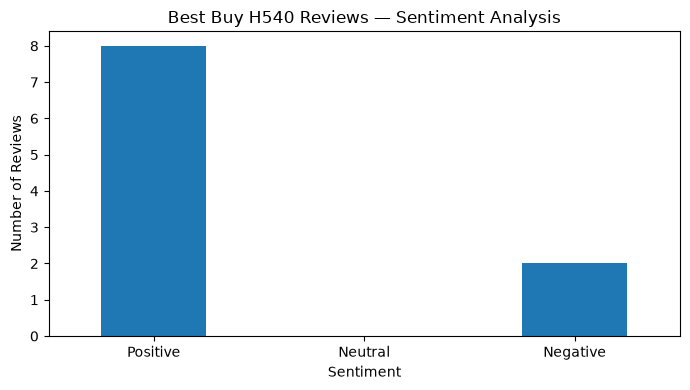

Unique genuine reviews: 10
Minimum required: 50
Minimum requirement met: False

Sentiment counts:
sentiment
Positive    8
Neutral     0
Negative    2
Name: count, dtype: int64

CSV saved: C:\Users\Administrator\Downloads\task1_reviews_sentiment.csv
Chart saved: C:\Users\Administrator\Downloads\bestbuy_sentiment_distribution.png

INCOMPLETE: This is a preliminary sample. Additional genuine reviews must be collected through an authorized, accessible method before submission.


In [24]:

# FINAL PROCESSING CELL — Sentiment analysis and deliverables

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Load the existing genuine review backup
input_path = Path("bestbuy_reviews_backup.csv")

if not input_path.exists():
    raise FileNotFoundError(
        "Backup CSV not found. Run the backup cell first."
    )

df = pd.read_csv(input_path)

if df.empty:
    raise ValueError("The review backup contains no records.")

# Validate required fields
required = [
    "title", "review_text", "date",
    "rating", "source", "reviewer_name"
]

missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Clean fields
for col in ["title", "review_text", "source", "reviewer_name"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

df["date"] = pd.to_datetime(
    df["date"], errors="coerce"
).dt.strftime("%Y-%m-%d").fillna("")

df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

# Remove duplicate review records
df = df.drop_duplicates(
    subset=["title", "review_text", "date", "rating", "reviewer_name"]
).reset_index(drop=True)

# Stable primary keys based on review content
import hashlib

def make_id(row):
    content = "|".join(
        str(row[col])
        for col in [
            "title", "review_text", "date",
            "rating", "reviewer_name"
        ]
    )
    return "BBCA-" + hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()[:16].upper()

df.insert(0, "primary_key", df.apply(make_id, axis=1))

# VADER sentiment analysis
analyzer = SentimentIntensityAnalyzer()

def classify_sentiment(text):
    score = analyzer.polarity_scores(str(text))["compound"]

    if score >= 0.05:
        label = "Positive"
    elif score <= -0.05:
        label = "Negative"
    else:
        label = "Neutral"

    return pd.Series({
        "sentiment_score": score,
        "sentiment": label
    })

df["combined_text"] = (
    df["title"] + ". " + df["review_text"]
).str.strip()

df[["sentiment_score", "sentiment"]] = (
    df["combined_text"].apply(classify_sentiment)
)

df["sentiment_method"] = "VADER"
df["source_url"] = (
    "https://www.bestbuy.ca/en-ca/product/"
    "logitech-logitech-usb-headset-h540-981-000510/"
    "10218414/review"
)

df.drop(columns=["combined_text"], inplace=True)

# Export results
csv_path = Path("task1_reviews_sentiment.csv")
df.to_csv(csv_path, index=False, encoding="utf-8-sig")

# Generate sentiment chart
counts = df["sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"],
    fill_value=0
)

ax = counts.plot(kind="bar", figsize=(7, 4))
ax.set_title("Best Buy H540 Reviews — Sentiment Analysis")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

chart_path = Path("bestbuy_sentiment_distribution.png")
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

# Validate the assignment's minimum review count
print("Unique genuine reviews:", len(df))
print("Minimum required:", 50)
print("Minimum requirement met:", len(df) >= 50)
print("\nSentiment counts:")
print(counts)
print("\nCSV saved:", csv_path.resolve())
print("Chart saved:", chart_path.resolve())

if len(df) < 50:
    print(
        "\nINCOMPLETE: This is a preliminary sample. "
        "Additional genuine reviews must be collected through "
        "an authorized, accessible method before submission."
    )


# Task 1: Best Buy Canada Review Scraping and Sentiment Analysis

## 1. Objective

The objective was to collect publicly available customer reviews for the Logitech H540 USB Headset for PC from Best Buy Canada, extract review details, and apply sentiment analysis to understand customer feedback.

## 2. Data Collection and Limitations

The product page displayed an average rating of 4.3 out of 5, based on more than 2,000 reviews at the time of inspection. Selenium and Beautiful Soup were used to inspect the publicly visible review content.

The parser successfully extracted 10 genuine reviews, including review titles, review text, dates, ratings, reviewer names, and source information. During automated collection, Best Buy returned an Access Denied response. The collection process was stopped rather than attempting to bypass the website's access controls.

Consequently, the current dataset is a preliminary sample and does not meet the requirement to collect more than 50 reviews. Additional collection requires an authorized method or an alternative approved by the assessment provider.

## 3. Sentiment Analysis Method

The VADER sentiment analyzer was applied to the review text. It generates a compound sentiment score ranging from -1 to +1. Scores of 0.05 or higher were classified as Positive, scores of -0.05 or lower as Negative, and scores between these thresholds as Neutral.

## 4. Preliminary Results

Of the 10 reviews analyzed:

- Positive: 8 reviews (80%)
- Negative: 2 reviews (20%)
- Neutral: 0 reviews (0%)

These results describe only the small sample and should not be generalized to all Best Buy customers.

## 5. Preliminary Business Insights

The positive reviews mention sound quality, convenience, microphone performance, and ease of use. Negative reviews raise concerns about comfort, sound quality, and cable stiffness.

Potential recommendations include evaluating long-term wearing comfort, testing microphone and audio performance, and reviewing cable durability. These are preliminary observations from the sample, not statistically representative findings.

## 6. Scraping Challenges and Mitigation

The automated browser received an Access Denied response even though the review page remained accessible in a regular browser. The scraper was stopped when the restriction appeared.

Recommended mitigations include checking the website's terms and access policies, using an authorized API or export if available, implementing bounded retries for temporary errors, adding reasonable request delays, and logging failures. CAPTCHA or access-control mechanisms should not be bypassed without explicit authorization.

## 7. Conclusion and Next Steps

The review extraction and sentiment-analysis pipeline was demonstrated successfully on 10 genuine reviews. Before final submission, the collection requirement must be addressed through an approved method, the results must be rerun on the verified dataset, and the final CSV and business insights must reflect the actual collected records.